In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
N = 10000
left, right = 1.0, 10.0

In [3]:
def f1(x):
    return x**2


def f2(x):
    return np.exp(x)


def f3(x):
    return -np.log(x)


def f4(x):
    return np.sqrt(1 + x**2)


functions = [f1, f2, f3, f4]

In [4]:
np.random.seed(0)  # For reproducibility

for f in functions:
    max_violation = -np.inf
    for _ in range(10_000):
        x = np.random.uniform(left, right, N)

        lam = np.random.rand(N)
        lam /= np.sum(lam)

        D = f(np.sum(lam * x)) - np.sum(lam * f(x))

        max_violation = max(max_violation, D)

    print(f"Maximum violation for {f.__name__}: {round(max_violation, 10)}")

Maximum violation for f1: -6.4904958369
Maximum violation for f2: -2031.4018532165
Maximum violation for f3: -0.1385497758
Maximum violation for f4: -0.029447232


In [5]:
np.random.seed(0)  # For reproducibility
max_violation_ln = -np.inf
for _ in range(10_000):
    x = np.random.uniform(left, right, N)
    expr = np.mean(x) - np.exp(np.mean(np.log(x)))
    max_violation_ln = max(max_violation_ln, expr)
print(f"Maximum violation for ln: {round(max_violation_ln, 10)}")

Maximum violation for ln: 0.7757925345


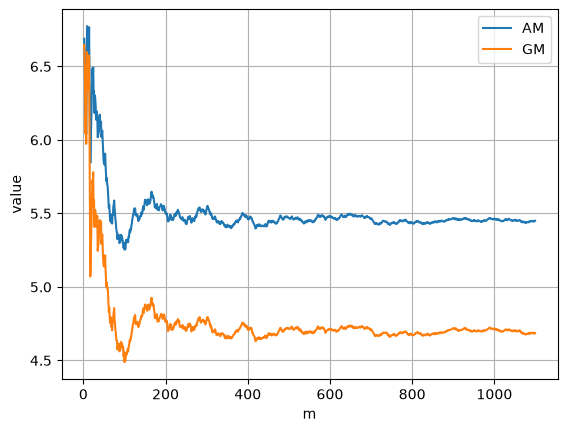

In [6]:
np.random.seed(0)

x_all = np.random.uniform(left, right, N)
m_values = np.arange(2, 1100)

AM_values = []
GM_values = []

for m in m_values:
    x = x_all[:m]

    AM = np.mean(x)
    GM = np.exp(np.mean(np.log(x)))

    AM_values.append(AM)
    GM_values.append(GM)

plt.plot(m_values, AM_values, label="AM")
plt.plot(m_values, GM_values, label="GM")

plt.xlabel("m")
plt.ylabel("value")

plt.legend()
plt.grid()
plt.show()

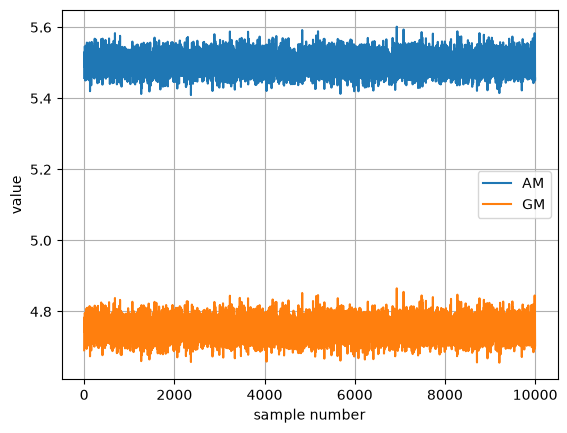

In [7]:
m = N

AM_values = []
GM_values = []

for _ in range(N):
    x = np.random.uniform(left, right, m)

    AM = np.mean(x)
    GM = np.exp(np.mean(np.log(x)))

    AM_values.append(AM)
    GM_values.append(GM)

plt.plot(AM_values, label="AM")
plt.plot(GM_values, label="GM")

plt.xlabel("sample number")
plt.ylabel("value")

plt.legend()
plt.grid()
plt.show()

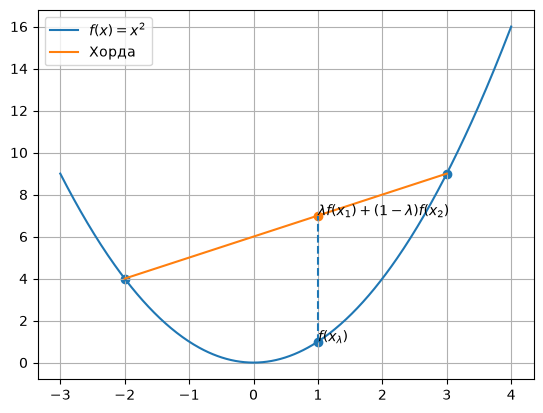

1.0
1.0
7.0


In [8]:
def f(x):
    return x**2


x1 = -2
x2 = 3

lam = 0.4

y1 = f(x1)
y2 = f(x2)

x_lam = lam * x1 + (1 - lam) * x2
y_lam = f(x_lam)
y_chord = lam * y1 + (1 - lam) * y2


x = np.linspace(-3, 4, 400)

plt.plot(x, f(x), label="$f(x)=x^2$")

plt.plot([x1, x2], [y1, y2], label="Хорда")

plt.scatter([x1, x2, x_lam], [y1, y2, y_lam])

plt.vlines(x_lam, y_lam, y_chord, linestyle="--")

plt.scatter(x_lam, y_chord)

plt.text(x_lam, y_lam, "$f(x_\\lambda)$")
plt.text(x_lam, y_chord, "$\\lambda f(x_1)+(1-\\lambda)f(x_2)$")

plt.grid()
plt.legend()
plt.show()

print(round(x_lam, 3))
print(round(y_lam, 3))
print(round(y_chord, 3))